# KAS Coarse-Grained force-field UQ

Optional package installation.


In [1]:
# %pip install numpy scipy matplotlib


In [23]:
from pathlib import Path
import csv
import hashlib
import json

import numpy as np
import matplotlib.pyplot as plt
from scipy import linalg
from scipy.spatial.distance import cdist

plt.rcParams['savefig.dpi'] = 300
np.random.seed(42)


### Settings

Select `QoI`, `chain` and `kernel`, then run the remaining cells.


In [24]:
QoI = 'local_twist_average'
# QoI = 'persistence_length'

chain = 0                          # 0, 1, or 2
kernel = 'sqexp'                    # 'sqexp' or 'matern25'
test_frac = 0.1                     # same sequential 90% / 10% split as DAS
d_max = 5
refit = False                      # reuse a matching KAS cache when available

# KAS settings, matching the reference implementation.
EPS = 1e-8
X_scale = 1.0
Y_scale = 1.0

if QoI not in {'local_twist_average', 'persistence_length'}:
    raise ValueError('Unknown quantity of interest')
if kernel not in {'sqexp', 'matern25'}:
    raise ValueError('kernel must be sqexp or matern25')
if not 0.0 < test_frac < 1.0:
    raise ValueError('test_frac must lie in (0, 1)')

# Works when launched from CGMD_UQ/ or its parent directory.
candidates = [Path.cwd(), Path.cwd() / 'CGMD_UQ']
BASE_DIR = next((p for p in candidates
                 if (p / 'data' / f'data_{QoI}_err_only_replicas.npz').is_file()), None)
if BASE_DIR is None:
    raise FileNotFoundError('Run from CGMD_UQ/ or its parent; data/*.npz is required.')
BASE_DIR = BASE_DIR.resolve()
DATA_DIR = BASE_DIR / 'data'
IMAGE_DIR = BASE_DIR / 'images' / 'kas'
RESULT_DIR = DATA_DIR / 'kas'
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)
tag = f'{QoI}_chain{chain}_{kernel}'
labels = {
    'local_twist_average': r'local twist average [$^{\circ}$]',
    'persistence_length': r'persistence length [$\mathring{A}$]',
}

def save_figure(fig, name, suffix='png'):
    fig.tight_layout()
    fig.savefig(IMAGE_DIR / f'kas_{name}_{tag}.{suffix}', bbox_inches='tight')


### Load data

Use finite replicas from the selected chain. Discard persistence lengths below 100 Å.


In [25]:
source_path = DATA_DIR / f'data_{QoI}_err_only_replicas.npz'
with np.load(source_path, allow_pickle=False) as data:
    x_raw = np.asarray(data['X'], dtype=np.float64)
    responses = np.asarray(data['Y'], dtype=np.float64)
    names = np.asarray(data['param_keys']).astype(str)
if responses.ndim == 1:
    responses = responses[:, None]
if not isinstance(chain, (int, np.integer)) or not 0 <= chain < responses.shape[1]:
    raise ValueError(f'chain must be an integer in [0, {responses.shape[1] - 1}]')
if x_raw.ndim != 2 or len(responses) != len(x_raw) or len(names) != x_raw.shape[1]:
    raise ValueError('Inconsistent input, response, or parameter-name shapes')
f_raw = responses[:, chain]
param_names = np.array([name[4:] if name.startswith('err_') else name for name in names])
valid = np.isfinite(x_raw).all(axis=1) & np.isfinite(f_raw)
if QoI == 'persistence_length':
    valid &= f_raw >= 100.0
x_raw, f_raw = x_raw[valid], f_raw[valid]
del responses
if len(x_raw) == 0:
    raise ValueError('No valid simulation replicas remain')


### Average replicas

Average identical parameter rows, preserving their first-occurrence order.


In [26]:
def average_replicas(x_raw, f_raw):
    unique, first, inverse, counts_sorted = np.unique(
        x_raw, axis=0, return_index=True, return_inverse=True, return_counts=True
    )
    first_order = np.argsort(first)
    sorted_to_first = np.empty(len(first_order), dtype=int)
    sorted_to_first[first_order] = np.arange(len(first_order))
    group = sorted_to_first[inverse]
    unique_x = unique[first_order]
    counts = counts_sorted[first_order]
    means = np.bincount(group, weights=f_raw) / counts
    # Keep the original replica values for the spread plot.
    grouped_f = f_raw[np.argsort(group, kind='stable')]
    boundaries = np.r_[0, np.cumsum(counts)]
    samples = {i: grouped_f[boundaries[i]:boundaries[i + 1]]
               for i in range(len(counts))}
    return unique_x, means, counts, samples

unique_x, mean_samples, counts, samples_per_param = average_replicas(x_raw, f_raw)
N, D = unique_x.shape
del x_raw, f_raw


Replica values and means, sorted by mean.


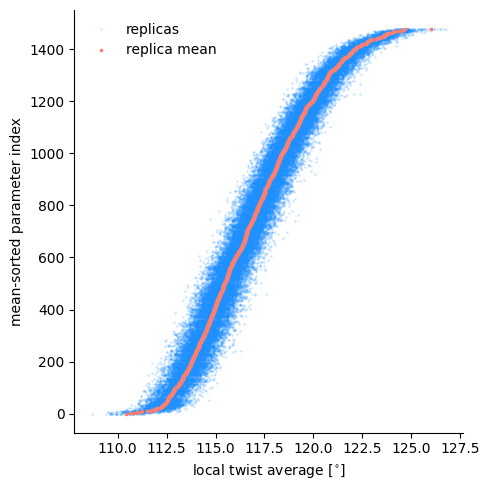

In [27]:
sorted_means = np.argsort(mean_samples)
fig, ax = plt.subplots(figsize=(5, 5))
replica_values = np.concatenate([samples_per_param[i] for i in sorted_means])
replica_positions = np.repeat(np.arange(1, N + 1), counts[sorted_means])
ax.plot(replica_values, replica_positions, '.', color='dodgerblue', alpha=0.15,
        markersize=2, label='replicas', rasterized=True)
ax.plot(mean_samples[sorted_means], np.arange(1, N + 1), 's', color='salmon',
        markersize=2, label='replica mean')
ax.set(xlabel=labels[QoI], ylabel='mean-sorted parameter index')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
save_figure(fig, 'samples')
plt.show()


### Split and normalize

Split unique parameter rows sequentially into training and validation sets. Fit input ranges and output mean/std on training rows only.


In [28]:
val_idx = int((1.0 - test_frac) * N)
if not 3 <= val_idx < N:
    raise ValueError('At least three training samples and one validation sample are required')
train_idx = np.arange(val_idx)
validation_idx = np.arange(val_idx, N)
x_min = unique_x[train_idx].min(axis=0)
x_max = unique_x[train_idx].max(axis=0)
x_range = x_max - x_min
constant_columns = x_range == 0
x = 2.0 * (unique_x - x_min) / np.where(constant_columns, 1.0, x_range) - 1.0
x[:, constant_columns] = 0.0
f_mean = float(mean_samples[train_idx].mean())
f_std = float(mean_samples[train_idx].std(ddof=1))
if not np.isfinite(f_std) or f_std <= 0:
    raise ValueError('Training outputs must have nonzero variance')
f = (mean_samples - f_mean) / f_std
x_train, x_val = x[train_idx], x[validation_idx]
f_train, f_val = f[train_idx], f[validation_idx]
d_max = min(d_max, D, val_idx - 1)
if d_max < 1:
    raise ValueError('d_max must be at least 1')


### KAS

Kernel bandwidths are median pairwise distances multiplied by `X_scale` and `Y_scale`.

$$A=K_x+n\varepsilon I,\qquad F=A^{-1}K_fA^{-1},\qquad
C_{KAS}=\frac1n\sum_k H_k^T F H_k.$$

Leading eigenvectors of $C_{KAS}$ define the active coordinates.


In [29]:
def kernel_values(squared_distance, length_scale, kind):
    if length_scale <= 0 or not np.isfinite(length_scale):
        raise ValueError('Kernel length scales must be finite and positive')
    q = np.maximum(np.asarray(squared_distance), 0.0) / length_scale**2
    if kind == 'sqexp':
        return np.exp(-0.5 * q)
    if kind == 'matern25':
        r = np.sqrt(5.0 * q)
        return (1.0 + r + r**2 / 3.0) * np.exp(-r)
    raise ValueError(f'Unknown kernel: {kind}')


def kernel_gradient_factor(squared_distance, length_scale, kind):
    if kind == 'sqexp':
        return kernel_values(squared_distance, length_scale, kind) / length_scale**2
    if kind == 'matern25':
        r = np.sqrt(5.0 * np.maximum(squared_distance, 0.0)) / length_scale
        return 5.0 / (3.0 * length_scale**2) * (1.0 + r) * np.exp(-r)
    raise ValueError(f'Unknown kernel: {kind}')


class KAS:
    def __init__(self, kernel='sqexp', EPS=1e-8, X_scale=1.0, Y_scale=1.0):
        if kernel not in {'sqexp', 'matern25'} or EPS <= 0:
            raise ValueError('Choose a supported kernel and positive EPS')
        if X_scale <= 0 or Y_scale <= 0:
            raise ValueError('Bandwidth multipliers must be positive')
        self.kernel, self.EPS = kernel, EPS
        self.X_scale, self.Y_scale = X_scale, Y_scale

    def fit(self, X, response):
        X = np.asarray(X, dtype=np.float64)
        response = np.asarray(response, dtype=np.float64).reshape(-1, 1)
        if X.ndim != 2 or len(X) != len(response) or len(X) < 2:
            raise ValueError('Expected at least two aligned training inputs and responses')
        if not np.isfinite(X).all() or not np.isfinite(response).all():
            raise ValueError('KAS requires finite inputs and responses')
        n = len(X)
        dx2 = cdist(X, X, metric='sqeuclidean')
        df2 = cdist(response, response, metric='sqeuclidean')
        # Include the diagonal, as in median_dist() in the reference code.
        self.SGX = self.X_scale * float(np.median(np.sqrt(dx2)))
        self.SGY = self.Y_scale * float(np.median(np.sqrt(df2)))
        Kx = kernel_values(dx2, self.SGX, self.kernel)
        Kf = kernel_values(df2, self.SGY, self.kernel)
        G = kernel_gradient_factor(dx2, self.SGX, self.kernel)
        Kx.flat[::n + 1] += n * self.EPS
        chol = linalg.cho_factor(Kx, lower=True, check_finite=False)
        left = linalg.cho_solve(chol, Kf, check_finite=False)
        F = linalg.cho_solve(chol, left.T, check_finite=False).T
        F = 0.5 * (F + F.T)

        # Exact expansion of sum_k H_k.T @ F @ H_k; centering reduces cancellation.
        Xc = X - X.mean(axis=0)
        Q = (G @ F) * G
        cross = Xc.T @ (Q @ Xc)
        C = (Xc.T @ (Q.sum(axis=1)[:, None] * Xc)
             - cross - cross.T + Xc.T @ ((F * (G.T @ G)) @ Xc)) / n
        self.C = 0.5 * (C + C.T)
        values, vectors = linalg.eigh(self.C, check_finite=False)
        values, vectors = values[::-1], vectors[:, ::-1]
        if not np.isfinite(values).all() or values[0] <= 0:
            raise FloatingPointError('KAS did not produce a finite positive spectrum')
        if values[-1] < -1e-7 * values[0]:
            raise FloatingPointError('Materially negative KAS eigenvalue; increase EPS')
        self.L = np.maximum(values, 0.0)  # remove negative roundoff only
        self.B = vectors.copy()
        # Deterministic signs make reruns easier to compare.
        largest = np.argmax(np.abs(self.B), axis=0)
        signs = np.sign(self.B[largest, np.arange(self.B.shape[1])])
        self.B *= np.where(signs == 0, 1.0, signs)
        return self

    def transform(self, X, d=1):
        if not 1 <= d <= self.B.shape[1]:
            raise ValueError('Requested dimension is outside the input dimension')
        return np.asarray(X) @ self.B[:, :d]


### Fit or load KAS

Reuse cached results when training data and settings match. Set `refit=True` to recompute.


In [30]:
cache_path = RESULT_DIR / f'kas_{tag}.npz'
settings = {'schema_version': 1, 'kernel': kernel, 'EPS': EPS,
            'X_scale': X_scale, 'Y_scale': Y_scale}
fingerprint = hashlib.sha256(json.dumps(settings, sort_keys=True).encode())
for array in (x_train, f_train):
    fingerprint.update(str(array.shape).encode())
    fingerprint.update(np.ascontiguousarray(array, dtype='<f8').tobytes())
cache_key = fingerprint.hexdigest()
kas = KAS(kernel=kernel, EPS=EPS, X_scale=X_scale, Y_scale=Y_scale)
loaded = False
if cache_path.exists() and not refit:
    with np.load(cache_path, allow_pickle=False) as saved:
        if str(saved['cache_key']) == cache_key:
            kas.C, kas.L, kas.B = saved['C'], saved['eigenvalues'], saved['eigenvectors']
            kas.SGX, kas.SGY = float(saved['SGX']), float(saved['SGY'])
            loaded = True
if not loaded:
    kas.fit(x_train, f_train)
    np.savez_compressed(
        cache_path, cache_key=cache_key, C=kas.C,
        eigenvalues=kas.L, eigenvectors=kas.B, SGX=kas.SGX, SGY=kas.SGY,
        settings=json.dumps(settings), x_min=x_min, x_max=x_max,
        f_mean=f_mean, f_std=f_std, train_idx=train_idx, validation_idx=validation_idx,
    )
C = kas.C
eigvals_C, eigvecs_C = kas.L, kas.B


### Fit GPs

Fit dimensions $d=1,\ldots,d_{\max}$ and select GP length scale and noise by training marginal likelihood.
Relative errors use standardized replica means:

$$\varepsilon=\frac{\|\mathbf f-\tilde{\mathbf f}\|_2^2}{\|\mathbf f\|_2^2}.$$


In [31]:
GP_LENGTH_SCALES = (0.1, 0.2, 0.4, 0.8, 1.6)
GP_NOISE_LEVELS = (0.05, 0.1, 0.2, 0.4, 0.8)  # standard deviations


def fit_gp(z_train, target, kind):
    z_train = np.asarray(z_train, dtype=float)
    target = np.asarray(target, dtype=float).ravel()
    z_mean, z_std = z_train.mean(axis=0), z_train.std(axis=0)
    z_std = np.where(z_std > 0, z_std, 1.0)
    z_scaled = (z_train - z_mean) / z_std
    distances = cdist(z_scaled, z_scaled, metric='sqeuclidean')
    n = len(target)
    best = None
    for length_scale in GP_LENGTH_SCALES:
        signal = kernel_values(distances, length_scale, kind)
        for noise in GP_NOISE_LEVELS:
            covariance = signal.copy()
            covariance.flat[::n + 1] += noise**2 + 1e-8
            chol = linalg.cho_factor(covariance, lower=True, check_finite=False)
            alpha = linalg.cho_solve(chol, target, check_finite=False)
            nll = float(0.5 * target @ alpha + np.log(np.diag(chol[0])).sum()
                        + 0.5 * n * np.log(2.0 * np.pi))
            if best is None or nll < best['nll']:
                best = dict(z_train=z_scaled, z_mean=z_mean, z_std=z_std,
                            length_scale=length_scale, noise=noise, kernel=kind,
                            chol=chol, alpha=alpha, nll=nll)
    return best


def predict_gp(model, z_predict, return_std=False, include_noise=True, return_cov=False):
    """Return the predictive mean and optionally its standard deviation or covariance."""
    z_predict = np.asarray(z_predict, dtype=float)
    z_scaled = (z_predict - model['z_mean']) / model['z_std']
    cross = kernel_values(cdist(model['z_train'], z_scaled, metric='sqeuclidean'),
                          model['length_scale'], model['kernel'])
    prediction = cross.T @ model['alpha']
    if not (return_std or return_cov):
        return prediction
    solved = linalg.solve_triangular(model['chol'][0], cross, lower=True,
                                     check_finite=False)
    if return_cov:
        covariance = kernel_values(
            cdist(z_scaled, z_scaled, metric='sqeuclidean'),
            model['length_scale'], model['kernel']) - solved.T @ solved
        covariance = 0.5 * (covariance + covariance.T)
        if include_noise:
            covariance.flat[::len(z_scaled) + 1] += model['noise']**2
        return prediction, covariance
    variance = np.maximum(1.0 - np.sum(solved**2, axis=0), 0.0)
    if include_noise:
        variance = variance + model['noise']**2
    return prediction, np.sqrt(variance)


def relative_error(prediction, target):
    denominator = float(np.sum(np.asarray(target)**2))
    return float(np.sum((prediction - target)**2) / denominator) if denominator > 0 else np.nan


models, train_loss, val_loss = {}, {}, {}
for dimension in range(1, d_max + 1):
    z_train = kas.transform(x_train, dimension)
    z_val = kas.transform(x_val, dimension)
    models[dimension] = fit_gp(z_train, f_train, kernel)
    train_loss[dimension] = relative_error(predict_gp(models[dimension], z_train), f_train)
    val_loss[dimension] = relative_error(predict_gp(models[dimension], z_val), f_val)
gp_fit_config = (QoI, chain, kernel)


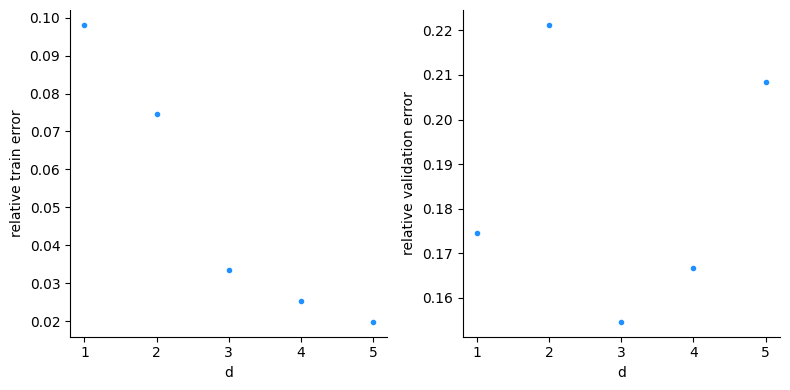

In [32]:
dimensions = np.arange(1, d_max + 1)
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, errors, ylabel in zip(axes, (train_loss, val_loss),
                              ('relative train error', 'relative validation error')):
    ax.plot(dimensions, [errors[i] for i in dimensions], '.', color='dodgerblue')
    ax.set(xlabel='d', ylabel=ylabel, xticks=dimensions, yscale='linear')
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(IMAGE_DIR / f'kas_errors_{tag}.png')
plt.show()
suggested_d = min(val_loss, key=val_loss.get)


Use `d=1` for a one-dimensional surrogate, or `d=suggested_d` for the lowest validation error.


In [33]:
d = 1
# d = suggested_d
model = models[d]


### Check kernel gradients

Compare analytic gradients with central finite differences.


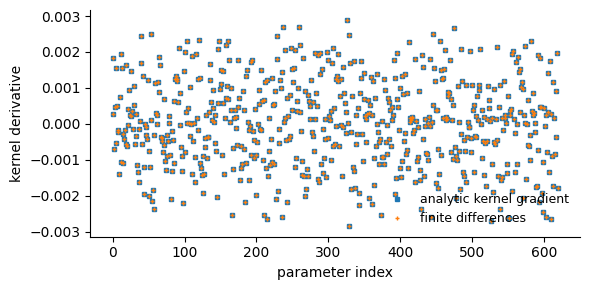

In [34]:
point, centre = x_train[0], x_train[1]
eps_fd = 1e-5
perturbations = eps_fd * np.eye(D)
plus = cdist(point[None, :] + perturbations, centre[None, :], metric='sqeuclidean')
minus = cdist(point[None, :] - perturbations, centre[None, :], metric='sqeuclidean')
fd_gradient = ((kernel_values(plus, kas.SGX, kernel)
                - kernel_values(minus, kas.SGX, kernel)) / (2.0 * eps_fd)).ravel()
squared_distance = float(np.sum((point - centre)**2))
analytic_gradient = -kernel_gradient_factor(squared_distance, kas.SGX, kernel) * (point - centre)
np.testing.assert_allclose(analytic_gradient, fd_gradient, rtol=1e-5, atol=1e-8)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(analytic_gradient, 's', markersize=3, label='analytic kernel gradient')
ax.plot(fd_gradient, '+', markersize=3, label='finite differences')
ax.set(xlabel='parameter index', ylabel='kernel derivative')
ax.legend(frameon=False, fontsize=9)
ax.spines[['top', 'right']].set_visible(False)
save_figure(fig, 'gradient_check')
plt.show()


### KAS spectrum

Check eigenpairs and plot eigenvalues relative to the leading value.


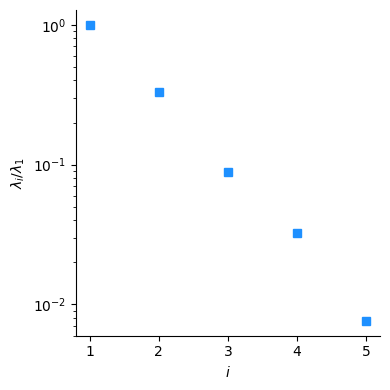

In [35]:
np.testing.assert_allclose(eigvecs_C.T @ eigvecs_C, np.eye(D), atol=1e-8)
eigenpair_residual = np.linalg.norm(C @ eigvecs_C - eigvecs_C * eigvals_C) / np.linalg.norm(C)
if eigenpair_residual > 1e-6:
    raise FloatingPointError(f'Unexpected eigenpair residual: {eigenpair_residual}')
n_plot = min(5, D)
fig, ax = plt.subplots(figsize=(4, 4))
ax.plot(np.arange(1, n_plot + 1),
        np.maximum(eigvals_C[:n_plot] / eigvals_C[0], np.finfo(float).tiny),
        's', color='dodgerblue')
ax.set(xlabel=r'$i$', ylabel=r'$\lambda_i / \lambda_1$', yscale='log',
       xticks=np.arange(1, n_plot + 1))
ax.spines[['top', 'right']].set_visible(False)
save_figure(fig, 'eigvals')
plt.show()


Project training and validation inputs onto the leading `d` KAS directions.


In [36]:
U_1 = eigvecs_C[:, :d]
y_train = kas.transform(x_train, d)
y_val = kas.transform(x_val, d)


### Surrogate

The 95% predictive band includes observation noise in replica means, conditional on the fitted KAS directions and GP hyperparameters. For `d>1`, other active coordinates are fixed at their training means.


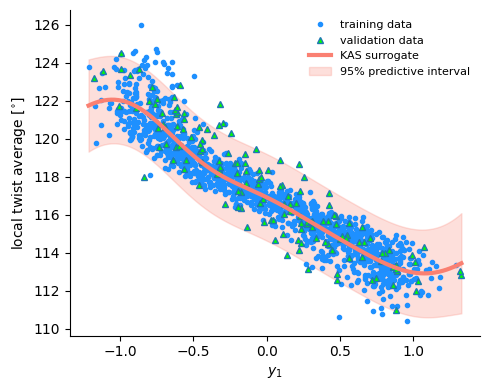

In [37]:
y_all = np.vstack([y_train, y_val])
y_lin = np.linspace(y_all[:, 0].min(), y_all[:, 0].max(), 200)
y_grid = np.tile(y_train.mean(axis=0), (len(y_lin), 1))
y_grid[:, 0] = y_lin
prediction, prediction_std = predict_gp(
    model, y_grid, return_std=True, include_noise=True
)
prediction_raw = prediction * f_std + f_mean
ci95 = 1.96 * prediction_std * f_std
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(y_train[:, 0], mean_samples[train_idx], '.', color='dodgerblue', label='training data')
ax.plot(y_val[:, 0], mean_samples[validation_idx], '^', markerfacecolor='lime',
        markeredgecolor='C0', markersize=4, label='validation data')
ax.plot(y_lin, prediction_raw, color='salmon', linewidth=3,
        label='KAS surrogate' if d == 1 else 'KAS–GP slice')
ax.fill_between(y_lin, prediction_raw - ci95, prediction_raw + ci95,
                color='salmon', alpha=0.25, label='95% predictive interval')
ax.set(xlabel=r'$y_1$',
       ylabel='persistence length' if QoI == 'persistence_length' else labels[QoI])
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, fontsize=8)
save_figure(fig, f'surrogate_d{d}')
plt.show()


### Activity scores

$$\nu_i^{(d)}=\sum_{j=1}^d\lambda_j U_{ij}^2,\qquad
\nu_i^{(\mathrm{all})}=(C_{KAS})_{ii}.$$

Set `use_all_modes=True` for full-spectrum scores. Scores refer to normalized input coordinates.


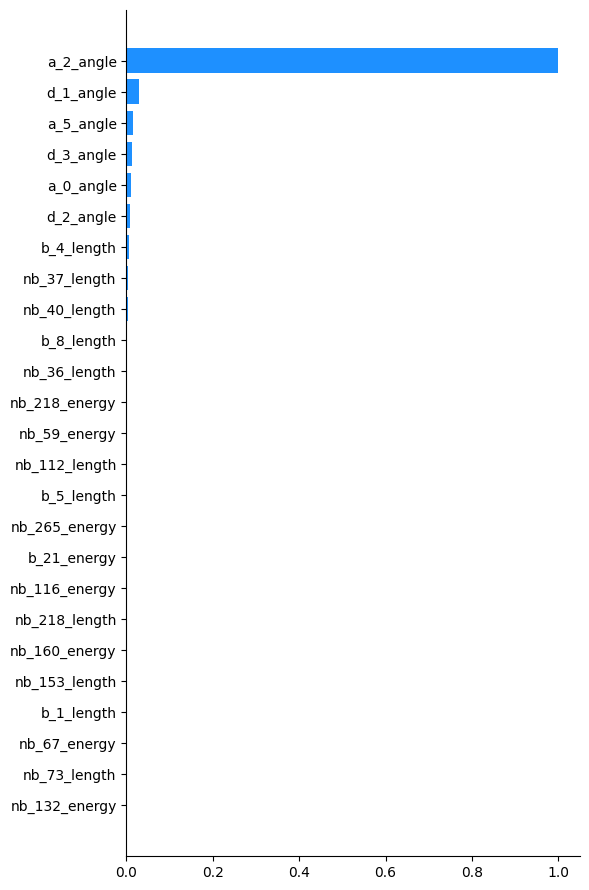

In [38]:
V_i = np.sum(eigvals_C[:d] * U_1**2, axis=1)
V_i_all = np.sum(eigvals_C * eigvecs_C**2, axis=1)
np.testing.assert_allclose(V_i_all, np.diag(C), rtol=1e-5,
                           atol=1e-7 * eigvals_C[0])
use_all_modes = False
scores = V_i_all if use_all_modes else V_i
ranking = np.argsort(scores)[::-1]
n_include = min(25, D)
selected = ranking[:n_include]
normalized_scores = scores / scores.max()
fig, ax = plt.subplots(figsize=(6, 9))
ax.barh(np.arange(n_include), normalized_scores[selected], color='dodgerblue', label='KAS')
ax.set_yticks(np.arange(n_include), labels=param_names[selected], fontsize=10)
ax.invert_yaxis()
ax.spines[['top', 'right']].set_visible(False)
save_figure(fig, f'activity_d{d}', suffix='pdf')
plt.show()


### Save results

Save predictions, scores and rankings using QoI, chain and kernel in filenames.


In [39]:
train_prediction = predict_gp(model, y_train) * f_std + f_mean
validation_prediction = predict_gp(model, y_val) * f_std + f_mean
np.savez_compressed(
    RESULT_DIR / f'kas_analysis_{tag}.npz',
    quantity=QoI, chain=chain, kernel=kernel, d=d, suggested_d=suggested_d,
    param_names=param_names, replica_counts=counts, response_mean=mean_samples,
    eigenvalues=eigvals_C, eigenvectors=eigvecs_C, C=C, U_1=U_1,
    train_idx=train_idx, validation_idx=validation_idx,
    x_min=x_min, x_max=x_max, f_mean=f_mean, f_std=f_std,
    dimensions=dimensions,
    train_loss=np.array([train_loss[i] for i in dimensions]),
    val_loss=np.array([val_loss[i] for i in dimensions]),
    y_train=y_train, y_val=y_val, activity_scores=V_i, activity_scores_all=V_i_all,
    y_grid=y_grid, prediction_mean=prediction_raw, prediction_ci95=ci95,
    prediction_interval_kind='predictive',
    prediction_std=prediction_std * f_std,
    gp_noise_std_raw=model['noise'] * f_std,
    train_prediction=train_prediction, validation_prediction=validation_prediction,
    gp_length_scale=model['length_scale'], gp_noise=model['noise'],
    gp_coordinate_mean=model['z_mean'], gp_coordinate_std=model['z_std'],
    gp_alpha=model['alpha'], SGX=kas.SGX, SGY=kas.SGY, EPS=EPS,
    X_scale=X_scale, Y_scale=Y_scale, cache_key=cache_key,
)
ranking_path = RESULT_DIR / f'kas_ranking_{tag}_d{d}.csv'
with ranking_path.open('w', newline='') as handle:
    writer = csv.writer(handle)
    writer.writerow(['rank', 'parameter', 'activity_retained', 'activity_all', 'normalized_plotted_score'])
    for rank, i in enumerate(ranking, 1):
        writer.writerow([rank, param_names[i], V_i[i], V_i_all[i], normalized_scores[i]])


### Posterior error: mean $\pm$ std

Reuse the selected QoI's data, KAS projection and fitted GPs. Compute relative errors for
2,000 joint posterior predictive draws, including observation noise by default.
Points show mean error and bars show $\pm1$ sample standard deviation (`ddof=1`).
These differ from errors of the GP posterior mean. The split and fitted parameters remain fixed.


In [40]:
GP_ERROR_DRAWS = 2000
GP_ERROR_SEED = 42
GP_ERROR_INCLUDE_NOISE = True
GP_ERROR_JITTER = 1e-10


def sample_gp_relative_errors(gp, coordinates, target, split, rng):
    mean, covariance = predict_gp(
        gp, coordinates, return_cov=True, include_noise=GP_ERROR_INCLUDE_NOISE)
    covariance.flat[::len(target) + 1] += GP_ERROR_JITTER
    factor = linalg.cholesky(covariance, lower=True, check_finite=False)
    draws = mean[:, None] + factor @ rng.standard_normal((len(target), GP_ERROR_DRAWS))

    losses, mean_errors, exact_means, exact_stds = [], [], [], []
    for rows in (slice(0, split), slice(split, len(target))):
        observed = target[rows]
        denominator = float(observed @ observed)
        if denominator <= 0:
            raise ValueError('Relative error needs a positive target sum of squares')
        residual = mean[rows] - observed
        block = covariance[rows, rows]
        losses.append(np.sum((draws[rows] - observed[:, None])**2, axis=0) / denominator)
        mean_errors.append(float(residual @ residual) / denominator)
        # Exact moments of the Gaussian quadratic error.
        exact_means.append((float(residual @ residual) + np.trace(block)) / denominator)
        variance = (2.0 * np.sum(block**2) + 4.0 * residual @ block @ residual) / denominator**2
        exact_stds.append(np.sqrt(max(float(variance), 0.0)))
    return tuple(map(np.asarray, (losses, mean_errors, exact_means, exact_stds)))


In [41]:
if gp_fit_config != (QoI, chain, kernel):
    raise ValueError('Settings changed; rerun the GP fitting cells.')

error_dimensions = dimensions.copy()
error_results = []
error_qoi_seed = 0 if QoI == 'local_twist_average' else 1
for dimension in error_dimensions:
    rng = np.random.default_rng(np.random.SeedSequence(
        [GP_ERROR_SEED, error_qoi_seed, int(dimension)]))
    error_results.append(sample_gp_relative_errors(
        models[dimension], kas.transform(x, int(dimension)), f, val_idx, rng))
error_samples, error_of_gp_mean, error_exact_mean, error_exact_std = map(
    np.stack, zip(*error_results))
error_mean = error_samples.mean(axis=-1)
error_std = error_samples.std(axis=-1, ddof=1)

if np.any(np.abs(error_mean - error_exact_mean) > 6.0 * error_exact_std / np.sqrt(GP_ERROR_DRAWS) + 1e-10):
    raise FloatingPointError('Sampled means disagree with exact Gaussian error moments')
if np.any(np.abs(error_std - error_exact_std) > 0.1 * error_exact_std + 1e-10):
    raise FloatingPointError('More posterior draws are needed for the standard deviations')

error_data_path = RESULT_DIR / f'kas_gp_error_posterior_{tag}.npz'
np.savez_compressed(
    error_data_path, quantities=[QoI], dimensions=error_dimensions,
    splits=['training', 'validation'],
    relative_error_samples=error_samples[None], relative_error_mean=error_mean[None],
    relative_error_std=error_std[None], relative_error_of_gp_mean=error_of_gp_mean[None],
    exact_relative_error_mean=error_exact_mean[None], exact_relative_error_std=error_exact_std[None],
    training_counts=[val_idx], validation_counts=[N - val_idx],
    response_means=[f_mean], response_stds=[f_std],
    gp_length_scales=[[models[i]['length_scale'] for i in error_dimensions]],
    gp_noise_stds=[[models[i]['noise'] for i in error_dimensions]],
    num_draws=GP_ERROR_DRAWS, random_seed=GP_ERROR_SEED,
    include_observation_noise=GP_ERROR_INCLUDE_NOISE, sampling_jitter=GP_ERROR_JITTER,
    chain=chain, kernel=kernel, test_frac=test_frac, cache_keys=[cache_key],
    relative_error_definition='sum((draw - standardized_target)**2) / sum(standardized_target**2)',
)
with error_data_path.with_suffix('.csv').open('w', newline='') as handle:
    writer = csv.writer(handle)
    writer.writerow(['quantity', 'd', 'split', 'mean', 'std', 'error_of_gp_mean',
                     'exact_mean', 'exact_std', 'num_draws', 'include_observation_noise'])
    for d_index, dimension in enumerate(error_dimensions):
        for split_index, split_name in enumerate(('training', 'validation')):
            index = (d_index, split_index)
            writer.writerow([QoI, dimension, split_name, error_mean[index], error_std[index],
                             error_of_gp_mean[index], error_exact_mean[index], error_exact_std[index],
                             GP_ERROR_DRAWS, GP_ERROR_INCLUDE_NOISE])
error_analysis_config = (QoI, chain, kernel)


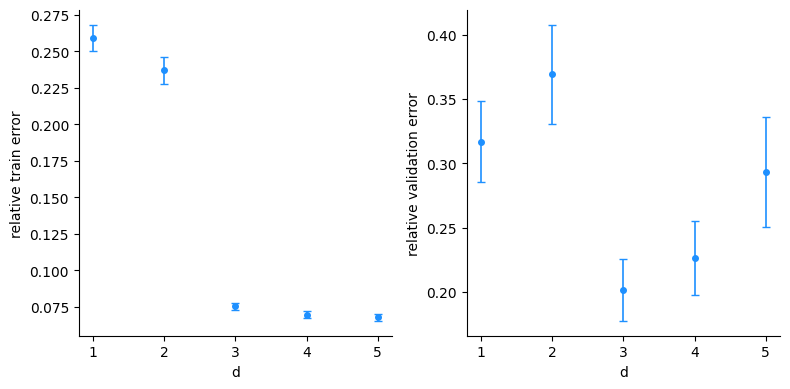

In [42]:
if error_analysis_config != (QoI, chain, kernel):
    raise ValueError('Settings changed; rerun the posterior error cell.')

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for split_index, (ax, ylabel) in enumerate(zip(
        axes, ('relative train error', 'relative validation error'))):
    ax.errorbar(error_dimensions, error_mean[:, split_index],
                yerr=error_std[:, split_index], fmt='.', color='dodgerblue',
                markersize=8, capsize=3, elinewidth=1.2, linestyle='none')
    ax.set(xlabel='d', ylabel=ylabel, xticks=error_dimensions, yscale='linear')
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
for suffix in ('png', 'pdf'):
    fig.savefig(IMAGE_DIR / f'kas_gp_error_posterior_{tag}.{suffix}')
plt.show()
